### CVAT Custom Dataset

Combines all manually annotated datasets exported from CVAT and trains YOLO11n.

- **Auto-detects** all folders in `datasets/` that start with `cvat_`.
- **Merges** them together into one master dataset.
- **Scene-aware split:** It groups images by their prefix (e.g., `20250326`, `14_43_front`) and holds out entire scenes for the validation set. This prevents "data leakage" and ensures the model can actually track bottles in unseen videos.

Outputs: Merged dataset, split dataset with `data.yaml`, trained model weights, and inline evaluation metrics.

In [1]:
from pathlib import Path
import shutil
import random
import torch
import yaml
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO
from collections import defaultdict
from collections import Counter

print(f"PyTorch: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
device = 0 if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATASETS_DIR = ROOT / "datasets"

MERGED_DIR = ROOT / "data" / "cvat_merged"
SPLIT_DIR = ROOT / "data" / "cvat_split"
RESULTS_DIR = ROOT / "results" / "cvat_training"
RUN_NAME = "yolo11n_cvat_all"

for d in [MERGED_DIR, SPLIT_DIR, RESULTS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print(f"Datasets folder: {DATASETS_DIR.relative_to(ROOT)}")

PyTorch: 2.14.1+cpu
CUDA available: False
Using device: cpu
Datasets folder: datasets


In [2]:
print("=" * 80)
print("CVAT DATASET INTEGRITY CHECK")
print("=" * 80)

cvat_folders = sorted([d for d in DATASETS_DIR.glob("cvat_*") if d.is_dir()])

if not cvat_folders:
    print("No CVAT folders found.")

for folder in cvat_folders:
    print(f"\nChecking: {folder.name}")
    print("-" * 80)

    # 1. Check for data.yaml
    yaml_path = folder / "data.yaml"
    num_classes = 0
    if not yaml_path.exists():
        print("  ❌ ERROR: data.yaml is missing.")
    else:
        try:
            cfg = yaml.safe_load(yaml_path.read_text())
            names = cfg.get("names", [])
            if isinstance(names, dict):
                num_classes = len(names)
            else:
                num_classes = len(names)
            print(f"  ✅ YAML: Found {num_classes} classes: {names}")
        except Exception as e:
            print(f"  ❌ ERROR: Could not parse data.yaml ({e})")

    # 2. Locate images and labels
    img_dir = folder / "images" / "train" if (folder / "images" / "train").exists() else folder / "images"
    lbl_dir = folder / "labels" / "train" if (folder / "labels" / "train").exists() else folder / "labels"

    if not img_dir.exists():
        print(f"  ❌ ERROR: Image directory not found ({img_dir.relative_to(folder)})")
        continue
    if not lbl_dir.exists():
        print(f"  ❌ ERROR: Label directory not found ({lbl_dir.relative_to(folder)})")
        continue

    # 3. Get lists of files
    images = {p.stem: p for p in img_dir.rglob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png"}}
    labels = {p.stem: p for p in lbl_dir.rglob("*.txt")}

    print(f"  ℹ️  Found {len(images)} images and {len(labels)} label files.")

    # 4. Cross-check files
    missing_labels = 0
    missing_images = 0
    empty_labels = 0
    invalid_format = 0
    invalid_classes = 0
    total_boxes = 0
    class_counts = Counter()

    for stem, img_path in images.items():
        if stem not in labels:
            missing_labels += 1
            continue

        lbl_path = labels[stem]
        text = lbl_path.read_text().strip()
        
        if not text:
            empty_labels += 1
            continue

        for line in text.splitlines():
            parts = line.split()
            if len(parts) != 5:
                invalid_format += 1
                continue
            
            cls_id = int(parts[0])
            if cls_id >= num_classes:
                invalid_classes += 1
                continue
                
            class_counts[cls_id] += 1
            total_boxes += 1

    for stem in labels.keys():
        if stem not in images:
            missing_images += 1

    # 5. Check train.txt (CVAT specific)
    train_txt = folder / "train.txt"
    train_txt_status = "Not found (optional)"
    if train_txt.exists():
        lines = train_txt.read_text().strip().splitlines()
        missing_in_txt = 0
        for img_name in images.keys():
            if not any(img_name in line for line in lines):
                missing_in_txt += 1
        if missing_in_txt > 0:
            train_txt_status = f"❌ {missing_in_txt} images are missing from train.txt"
        else:
            train_txt_status = "✅ All images listed in train.txt"

    # 6. Print Results
    if missing_labels == 0:
        print("  ✅ Every image has a matching label file.")
    else:
        print(f"  ⚠️ WARNING: {missing_labels} images have NO label file (empty annotations).")
        
    if missing_images > 0:
        print(f"  ❌ ERROR: {missing_images} label files have NO matching image.")
        
    if empty_labels > 0:
        print(f"  ⚠️ WARNING: {empty_labels} label files are completely empty.")
        
    if invalid_format > 0:
        print(f"  ❌ ERROR: {invalid_format} lines in label files do not have exactly 5 values.")
        
    if invalid_classes > 0:
        print(f"  ❌ ERROR: {invalid_classes} bounding boxes use a class ID that does not exist in data.yaml.")
        
    print(f"  ✅ Total valid bounding boxes: {total_boxes}")
    if class_counts:
        print(f"  📊 Class distribution: {dict(class_counts)}")
    print(f"  📄 train.txt: {train_txt_status}")

print("\n" + "=" * 80)

CVAT DATASET INTEGRITY CHECK

Checking: cvat_batch_1a
--------------------------------------------------------------------------------
  ✅ YAML: Found 1 classes: {0: 'gas-bottles'}
  ℹ️  Found 111 images and 111 label files.
  ✅ Every image has a matching label file.
  ✅ Total valid bounding boxes: 189
  📊 Class distribution: {0: 189}
  📄 train.txt: ✅ All images listed in train.txt

Checking: cvat_batch_1b
--------------------------------------------------------------------------------
  ✅ YAML: Found 1 classes: {0: 'gas-bottles'}
  ℹ️  Found 210 images and 192 label files.
  ⚠️ WARNING: 18 images have NO label file (empty annotations).
  ✅ Total valid bounding boxes: 239
  📊 Class distribution: {0: 239}
  📄 train.txt: ✅ All images listed in train.txt

Checking: cvat_batch_2
--------------------------------------------------------------------------------
  ✅ YAML: Found 1 classes: {0: 'gas-bottles'}
  ℹ️  Found 72 images and 63 label files.
  ⚠️ WARNING: 9 images have NO label file (em

### Merge CVAT Batches
Finds every folder in `datasets/` that starts with `cvat_`, and copies all images and labels into a single `data/cvat_merged/` folder.

In [3]:
if MERGED_DIR.exists():
    shutil.rmtree(MERGED_DIR)
(MERGED_DIR / "images").mkdir(parents=True, exist_ok=True)
(MERGED_DIR / "labels").mkdir(parents=True, exist_ok=True)

cvat_folders = sorted([d for d in DATASETS_DIR.glob("cvat_*") if d.is_dir()])
print(f"Found {len(cvat_folders)} CVAT batch folders:")
for d in cvat_folders:
    print(f"  - {d.name}")

EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

merged_images = []
class_names = set()

for folder in cvat_folders:
    # Read classes from this folder's data.yaml if it exists
    yaml_path = folder / "data.yaml"
    if yaml_path.exists():
        cfg = yaml.safe_load(yaml_path.read_text())
        names = cfg.get("names", [])
        for n in (names.values() if isinstance(names, dict) else names):
            class_names.add(n)

    # CVAT exports can nest images in 'train' or just put them directly in 'images'
    img_dir = folder / "images" / "train" if (folder / "images" / "train").exists() else folder / "images"
    lbl_dir = folder / "labels" / "train" if (folder / "labels" / "train").exists() else folder / "labels"

    for img in img_dir.rglob("*"):
        if img.is_file() and img.suffix.lower() in EXTS:
            lbl = lbl_dir / f"{img.stem}.txt"
            
            # Only keep if the label file exists and has content (is actually annotated)
            if lbl.exists() and lbl.stat().st_size > 0:
                # Handle potential name clashes by prefixing with batch name
                new_name = f"{folder.name}_{img.name}"
                shutil.copy2(img, MERGED_DIR / "images" / new_name)
                shutil.copy2(lbl, MERGED_DIR / "labels" / f"{folder.name}_{img.stem}.txt")
                merged_images.append(new_name)

print(f"\nMerged {len(merged_images)} annotated images.")
print(f"Classes detected: {list(class_names)}")

Found 3 CVAT batch folders:
  - cvat_batch_1a
  - cvat_batch_1b
  - cvat_batch_2

Merged 366 annotated images.
Classes detected: ['gas-bottles']


### Scene-Aware Train/Val Split
To ensure the model works on video tracking, we must not put frames from the same video in both train and val.

We extract the scene prefix from the filename (e.g., `14_43_front` or `20250326`). We then hold out entire scenes for the validation set (approx 20%).

In [4]:
def get_scene(name):
    # Matches patterns like 14_43_front, 14_55_back_left, 20250326
    parts = name.split('_')
    if parts[0].isdigit() and len(parts[0]) == 8: # Date format
        return parts[0]
    elif parts[0].isdigit() and len(parts[0]) == 2: # Video time format
        return "_".join(parts[:3])
    return parts[0] # fallback

scene_groups = defaultdict(list)
for img_name in merged_images:
    scene = get_scene(img_name.replace("cvat_batch_1a_", "").replace("cvat_batch_1b_", "").replace("cvat_batch_2_", ""))
    scene_groups[scene].append(img_name)

print("Scenes found in dataset:")
for scene, imgs in scene_groups.items():
    print(f"  {scene}: {len(imgs)} images")

# Shuffle scenes to pick one for validation
scenes = list(scene_groups.keys())
random.seed(42)
random.shuffle(scenes)

# Aim for ~20% of images in validation
total_imgs = len(merged_images)
target_val = int(total_imgs * 0.2)
val_count = 0
val_scenes = []

for scene in scenes:
    if val_count < target_val:
        val_scenes.append(scene)
        val_count += len(scene_groups[scene])

print(f"\nHolding out these scenes for validation: {val_scenes}")

# Split into folders
for split in ["train", "valid"]:
    (SPLIT_DIR / split / "images").mkdir(parents=True, exist_ok=True)
    (SPLIT_DIR / split / "labels").mkdir(parents=True, exist_ok=True)

train_count, val_count = 0, 0

for img_name in merged_images:
    scene = get_scene(img_name.replace("cvat_batch_1a_", "").replace("cvat_batch_1b_", "").replace("cvat_batch_2_", ""))
    split = "valid" if scene in val_scenes else "train"
    
    shutil.copy2(MERGED_DIR / "images" / img_name, SPLIT_DIR / split / "images" / img_name)
    lbl_name = img_name.rsplit('.', 1)[0] + ".txt"
    shutil.copy2(MERGED_DIR / "labels" / lbl_name, SPLIT_DIR / split / "labels" / lbl_name)
    
    if split == "train": train_count += 1
    else: val_count += 1

print(f"\nFinal split: Train={train_count}, Valid={val_count}")

Scenes found in dataset:
  20250326: 111 images
  frame: 192 images
  Automatic LPG Cylinder filling plant. #Shorts: 16 images
  Bolivia： FLEXSPEED for Side-Entry Valves (2014): 42 images
  LPG CYLINDER FILLING CAROUSEL (ELECTRONIC 36 sec.): 5 images

Holding out these scenes for validation: ['Bolivia： FLEXSPEED for Side-Entry Valves (2014)', 'frame']

Final split: Train=132, Valid=234


### Write YAML
Writes a `data.yaml` for Ultralytics based on the detected classes.

In [5]:
# Ensure we have a clean list of class names
if not class_names:
    class_names = ["gas-bottle"] # fallback
class_names = sorted(list(class_names))

yaml_content = {
    "path": str(SPLIT_DIR),
    "train": "train/images",
    "val": "valid/images",
    "nc": len(class_names),
    "names": class_names
}

yaml_path = SPLIT_DIR / "data.yaml"
yaml_path.write_text(yaml.safe_dump(yaml_content, sort_keys=False))

print(f"Saved {yaml_path.relative_to(ROOT)}")
print(yaml_path.read_text())

Saved data\cvat_split\data.yaml
path: d:\BCS Files\Y3S1\AI Applications MBI38j\Labs\primagaz-yolo\data\cvat_split
train: train/images
val: valid/images
nc: 1
names:
- gas-bottles



### Train YOLO11n
We train on the merged, scene-split dataset.

In [6]:
EPOCHS = 25
IMGSZ = 416
BATCH = 2
WORKERS = 0

model = YOLO("yolo11n.pt")

model.train(
    data=str(yaml_path),
    epochs=EPOCHS,
    imgsz=IMGSZ,
    batch=BATCH,
    workers=WORKERS,
    device=device,
    project=str(RESULTS_DIR),
    name=RUN_NAME,
    exist_ok=True,
    plots=True,
    seed=42,
    cache=False,  # Do NOT load all images into RAM at once
)

RUN_DIR = RESULTS_DIR / RUN_NAME
print(f"Run directory: {RUN_DIR.relative_to(ROOT)}")

New https://pypi.org/project/ultralytics/8.4.181 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.175  Python-3.11.9 torch-2.14.1+cpu CPU (AMD Ryzen 7 6800HS with Radeon Graphics)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=d:\BCS Files\Y3S1\AI Applications MBI38j\Labs\primagaz-yolo\data\cvat_split\data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_r

### Evaluation & Examples
Load the best weights, print the validation metrics, and display a few annotated predictions inline.

Ultralytics 8.4.175  Python-3.11.9 torch-2.14.1+cpu CPU (AMD Ryzen 7 6800HS with Radeon Graphics)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0.10.0 ms, read: 1677.2467.0 MB/s, size: 676.0 KB)
val: Scanning D:\BCS Files\Y3S1\AI Applications MBI38j\Labs\primagaz-yolo\data\cvat_split\valid\labels.cache... 234 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 234/234  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 117/117 9.8it/s 12.0s<0.1s
                   all        234        405      0.831      0.677      0.734      0.532
Speed: 0.3ms preprocess, 21.2ms inference, 0.0ms loss, 0.8ms postprocess per image
Results saved to D:\BCS Files\Y3S1\AI Applications MBI38j\Labs\primagaz-yolo\notebooks\runs\detect\val-6
STANDALONE VALIDATION — MERGED CVAT DATASET
Precision: 0.8312
Recall:    0.6765
mAP50:     0.7345
mAP50-95:  0.5320

Last-epoch training metric

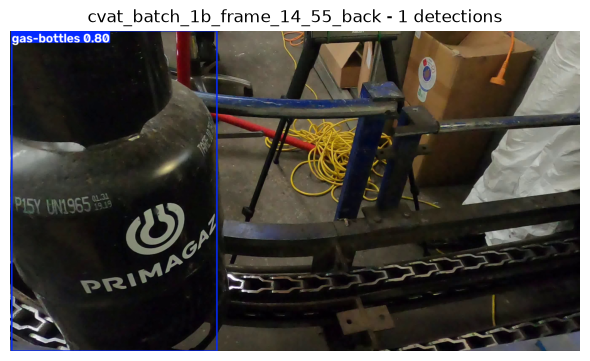

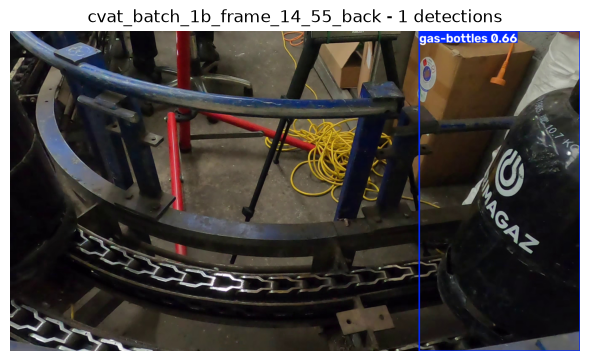

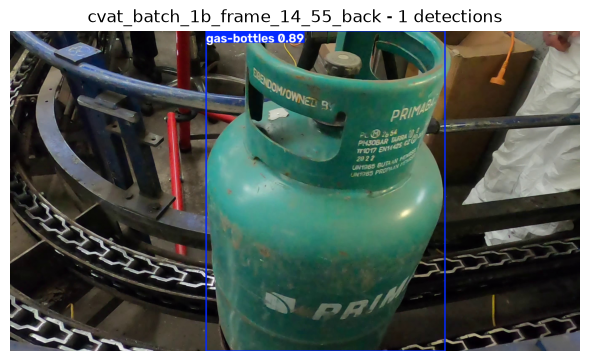

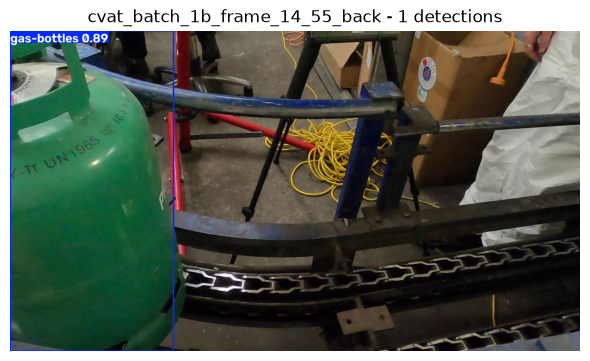

Annotated images saved to results\cvat_training\annotated


In [7]:
import pandas as pd

BEST_PT = RUN_DIR / "weights" / "best.pt"
eval_model = YOLO(str(BEST_PT))

# 1. Run Validation
val_metrics = eval_model.val(
    data=str(yaml_path), split="val", imgsz=IMGSZ, batch=BATCH, device=device, verbose=False
)

print("=" * 60)
print("STANDALONE VALIDATION — MERGED CVAT DATASET")
print("=" * 60)
print(f"Precision: {val_metrics.box.mp:.4f}")
print(f"Recall:    {val_metrics.box.mr:.4f}")
print(f"mAP50:     {val_metrics.box.map50:.4f}")
print(f"mAP50-95:  {val_metrics.box.map:.4f}")
print("=" * 60)

# 2. Read last-epoch training metrics
df = pd.read_csv(RUN_DIR / "results.csv")
df.columns = [c.strip() for c in df.columns]
last = df.iloc[-1]
print("\nLast-epoch training metrics:")
print(f"  Train Box Loss: {last['train/box_loss']:.4f}")
print(f"  Val Box Loss:   {last['val/box_loss']:.4f}")

# 3. Show Examples
ANNOTATED_DIR = RESULTS_DIR / "annotated"
ANNOTATED_DIR.mkdir(parents=True, exist_ok=True)

val_images = sorted((SPLIT_DIR / "valid" / "images").glob("*.jpg"))[:4]

print("\nGenerating predictions...")
for img_path in val_images:
    res = eval_model.predict(source=str(img_path), conf=0.25, imgsz=IMGSZ, device=device, verbose=False)[0]
    annotated = res.plot()
    cv2.imwrite(str(ANNOTATED_DIR / f"pred_{img_path.name}"), annotated)
    
    rgb = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.imshow(rgb)
    ax.axis("off")
    ax.set_title(f"{img_path.name[:30]} - {len(res.boxes)} detections")
    plt.tight_layout()
    plt.show()

print(f"Annotated images saved to {ANNOTATED_DIR.relative_to(ROOT)}")